# Interpretabilidade do modelo — por que o detector acusa o que acusa

**Projeto Integrado em Ciência de Dados (ECD-108) — Módulo 4**  
PPGMCS/UNIMONTES · Prof.ª Luciana Balieiro Cosme  
Aluno: **Samuel Rodrigues Gonçalves** · execução individual autorizada pela professora  
Outubro de 2026

---

O relatório de modelagem (`02_modelagem.ipynb`) termina com um número: o detector acusa 8 dos 18
ataques do conjunto de teste, a 0,43 alarme falso por hora. Esse número não diz **por que**. Um
operador de sala de controle que recebe o alarme precisa saber o que o disparou, e a banca vai
perguntar por que o modelo classificou uma janela específica como ataque.

Este caderno responde isso com **SHAP**, em dois níveis:

- **global** — quais variáveis o modelo valoriza no conjunto todo;
- **local** — por que **esta** janela foi classificada assim, com gráfico *waterfall*.

E usa a mesma ferramenta para examinar o achado central do M3: os ataques de **ponto interno**,
que nenhuma abordagem detecta. A pergunta aqui é se o modelo *quase* vê esses ataques — e a
resposta tem consequência prática direta.

In [1]:
import sys, json, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')   # antes do shap: evita aviso de widget do tqdm
import shap
SEMENTE = 42
np.random.seed(SEMENTE)

RAIZ = Path.cwd()
while not (RAIZ / 'src').is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
FIGS = RAIZ / 'reports' / 'figures'; FIGS.mkdir(parents=True, exist_ok=True)

from src import avaliacao as av
from src import rotulos as rt
from src import shap_util as su

print(f'pacotes carregados · semente {SEMENTE} · {len(list(RAIZ.glob("src/*.py")))} módulos em src/')

pacotes carregados · semente 42 · 6 módulos em src/


In [2]:
import matplotlib, matplotlib.pyplot as plt
S1, S2, S3, S8 = '#2a78d6', '#eb6834', '#2f9e74', '#e34948'
SURF, TXT, TXT2, GRID, NEU = '#fcfcfb', '#0b0b0b', '#52514e', '#e3e2df', '#c8ccd1'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID,
    'axes.labelcolor': TXT2, 'text.color': TXT, 'xtick.color': TXT2, 'ytick.color': TXT2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 130})

def titulo(fig, t, s):
    fig.text(.005, 1.13, t, ha='left', fontsize=12.5, fontweight='bold', color=TXT)
    fig.text(.005, 1.03, s, ha='left', fontsize=9.5, color=TXT2)

import re
TRADUZ = [(r"^Sum of (\d+) other features$", r"soma das outras \1 variáveis"),
          (r"^(\d+) other features$", r"outras \1 variáveis"),
          (r"^High$", "alto"), (r"^Low$", "baixo"),
          (r"E\[f\(X\)\]", "base"),
          (r"f\(x\)", "saída")]

def _troca(t):
    limpo = t.replace("$", "")
    for padrao, novo in TRADUZ:
        if re.search(padrao, limpo):
            return re.sub(padrao, novo, limpo)
    return t

def traduzir(fig):
    # a biblioteca shap rotula em ingles; o usuario do dashboard le portugues.
    # os rotulos de tick precisam ser reinstalados, nao apenas reescritos: o
    # matplotlib regenera o texto do tick no momento do desenho.
    for ax in fig.axes:
        for eixo in (ax.yaxis, ax.xaxis):
            antigos = [t.get_text() for t in eixo.get_ticklabels()]
            novos = [_troca(t) for t in antigos]
            if novos != antigos:
                eixo.set_ticks(eixo.get_ticklocs())
                eixo.set_ticklabels(novos)
        for t in [*ax.texts, ax.yaxis.label, ax.xaxis.label]:
            t.set_text(_troca(t.get_text()))
    return fig

## 0. O modelo e os dados

O modelo final do M3 vem serializado em `models/`: um `Pipeline(StandardScaler, LogisticRegression)`
com `class_weight='balanced'` e `C = 0,00562`, sobre janelas de 60 s com passo de 30 s. Junto vem o
limiar de alarme calibrado no trecho de validação.

Os dados que este caderno usa estão em `data/processed/`, em parquet: são as janelas já prontas,
geradas por `scripts/preparar_dados.py` a partir dos CSV brutos. Os CSV não são versionados.

In [3]:
modelo = pickle.loads((RAIZ / 'models' / 'modelo_final_logistica.pkl').read_bytes())
pipeline, LIMIAR, COLUNAS = modelo['modelo'], modelo['limiar'], modelo['colunas']

PROC = RAIZ / 'data' / 'processed'
teste = pd.read_parquet(PROC / 'janelas_teste.parquet')
fundo = pd.read_parquet(PROC / 'fundo_shap.parquet')[COLUNAS]
seg = pd.read_parquet(PROC / 'rotulo_segundo_teste.parquet')
ataques = pd.read_csv(RAIZ / 'data' / 'externo' / 'ataques_teste.csv')
meta = json.loads((PROC / 'meta.json').read_text())

X = teste[COLUNAS]
prob = pipeline.predict_proba(X)[:, 1]
teste['prob'] = prob
teste['alarme'] = (prob >= LIMIAR).astype(int)
print(f'{len(teste):,} janelas de teste · {X.shape[1]} features · limiar de alarme = {LIMIAR:.4f}'.replace(',', '.'))
print(f'janelas rotuladas como ataque: {teste.rotulo.sum()} · janelas com alarme: {teste.alarme.sum()}')

3.071 janelas de teste · 192 features · limiar de alarme = 0.9331
janelas rotuladas como ataque: 185 · janelas com alarme: 120


---

## 1. Por que o SHAP aqui é exato, e não aproximado

SHAP costuma ser caro porque, no caso geral, o valor de Shapley de cada feature exige somar sobre
todas as coalizões de features — daí o `KernelExplainer` e sua amostragem. **Para um modelo linear
isso não é necessário:** existe forma fechada.

Com `z = (x − média)/desvio` (o `StandardScaler` ajustado no treino) e o logito
`f(x) = intercepto + Σᵢ coefᵢ·zᵢ`, a contribuição de cada variável é

$$\phi_i = \text{coef}_i \cdot (z_i - \mathbb{E}[z_i]), \qquad
\text{base} = \text{intercepto} + \sum_i \text{coef}_i\,\mathbb{E}[z_i]$$

e vale **exatamente** `base + Σφᵢ = f(x)`. Três consequências práticas:

1. **É exato** — nenhuma amostragem, nenhum intervalo de confiança sobre a explicação.
2. **É instantâneo** — o dashboard pode recalcular a explicação a cada clique.
3. **Cada φᵢ pertence a uma variável original** — o escalonamento é linear por coluna, então o
   gráfico pode mostrar o nome e o valor na unidade de engenharia, que é o que o operador lê.

Os valores saem em **log-odds**: positivo empurra a janela para "ataque", negativo para "normal".
A implementação está em `src/shap_util.py`. A célula abaixo confere a identidade acima contra o
`decision_function` do próprio scikit-learn — é o teste que mostra que a explicação não é uma
aproximação simpática.

> Nos gráficos *waterfall* que vêm a seguir, **base** é o logito da operação típica (a média sobre o
> conjunto de fundo) e **saída** é o logito desta janela. As barras são o caminho de um ao outro.

In [4]:
explicador = su.ExplicadorLinear(pipeline, fundo)
erro = explicador.conferir_aditividade(X)
print(f'base (log-odds da operação típica): {explicador.base:.4f}')
print(f'erro máximo |base + Σφ − logito| sobre as {len(X)} janelas: {erro:.2e}')
assert erro < 1e-4, 'a decomposição deveria ser exata'
explicacao = explicador(X)
print('matriz SHAP:', explicacao.values.shape)

base (log-odds da operação típica): -1.4548
erro máximo |base + Σφ − logito| sobre as 3071 janelas: 1.34e-06
matriz SHAP: (3071, 192)


O erro é da ordem de 10⁻⁶ — resíduo de precisão de ponto flutuante das features em `float32`,
não de método. A decomposição é a própria conta do modelo, reescrita.

> **Nota de leitura.** O limiar de alarme é 0,933 em probabilidade, o que em log-odds fica em
> ≈ +2,64. Como a base é negativa, uma janela só dispara alarme quando a soma das contribuições
> positivas supera a base por uma margem larga. É isso que os gráficos abaixo mostram acontecendo —
> ou não acontecendo.

---

## 2. SHAP global — o que o modelo valoriza

### 2.1 As 15 features de maior peso

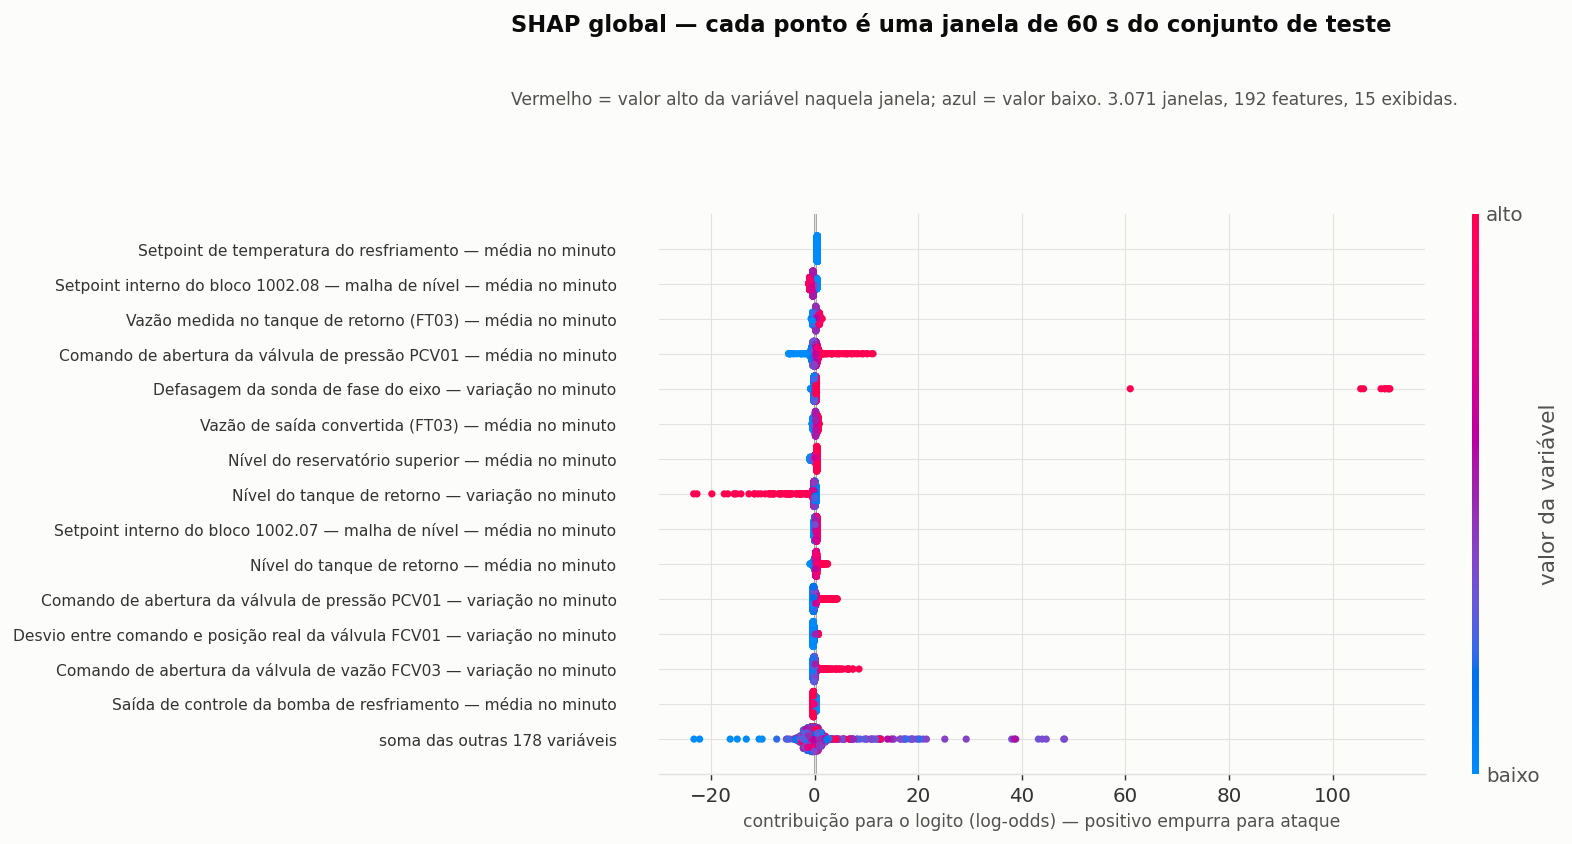

In [5]:
X_legivel = X.rename(columns=rt.mapa(COLUNAS))
expl_legivel = shap.Explanation(values=explicacao.values, base_values=explicacao.base_values,
                                data=X.to_numpy(), feature_names=list(X_legivel.columns))

plt.figure()
shap.plots.beeswarm(expl_legivel, max_display=15, show=False, color_bar_label='valor da variável')
fig = traduzir(plt.gcf()); fig.set_size_inches(9.5, 5.6)
ax = plt.gca(); ax.set_xlabel('contribuição para o logito (log-odds) — positivo empurra para ataque', fontsize=9.5)
ax.tick_params(axis='y', labelsize=8.6)
titulo(fig, 'SHAP global — cada ponto é uma janela de 60 s do conjunto de teste',
       'Vermelho = valor alto da variável naquela janela; azul = valor baixo. 3.071 janelas, 192 features, 15 exibidas.')
fig.savefig(FIGS / 'h1_beeswarm.png', bbox_inches='tight'); plt.show()

Três leituras desse gráfico, todas com consequência:

1. **O topo é dominado por comando de atuador e por setpoint interno da malha** — abertura da
   válvula de pressão PCV01, setpoint do resfriamento, setpoint interno da malha de nível. É
   coerente com o modelo de ataque do dataset: o atacante manipula setpoint e comando, não o sensor.
2. **A cor mostra a direção.** Nas variáveis do topo, os pontos vermelhos (valor alto) ficam à
   direita: valor alto empurra para "ataque". Isso dá uma regra que o operador entende sem saber o
   que é um logito.
3. **A cauda é longa.** Nenhuma variável resolve sozinha — exatamente o que a EDA do M2 já indicava
   com a correlação máxima de 0,199 contra o alvo.

### 2.2 O mesmo, agregado por equipamento

192 features vêm de 64 variáveis físicas: para cada uma, a **média**, a **variação** (desvio-padrão
móvel) e a **tendência** (último menos primeiro segundo) dentro da janela. Para quem opera a planta,
as três são o mesmo equipamento. Somar o |SHAP| médio por tag dá a leitura que vai para o dashboard.

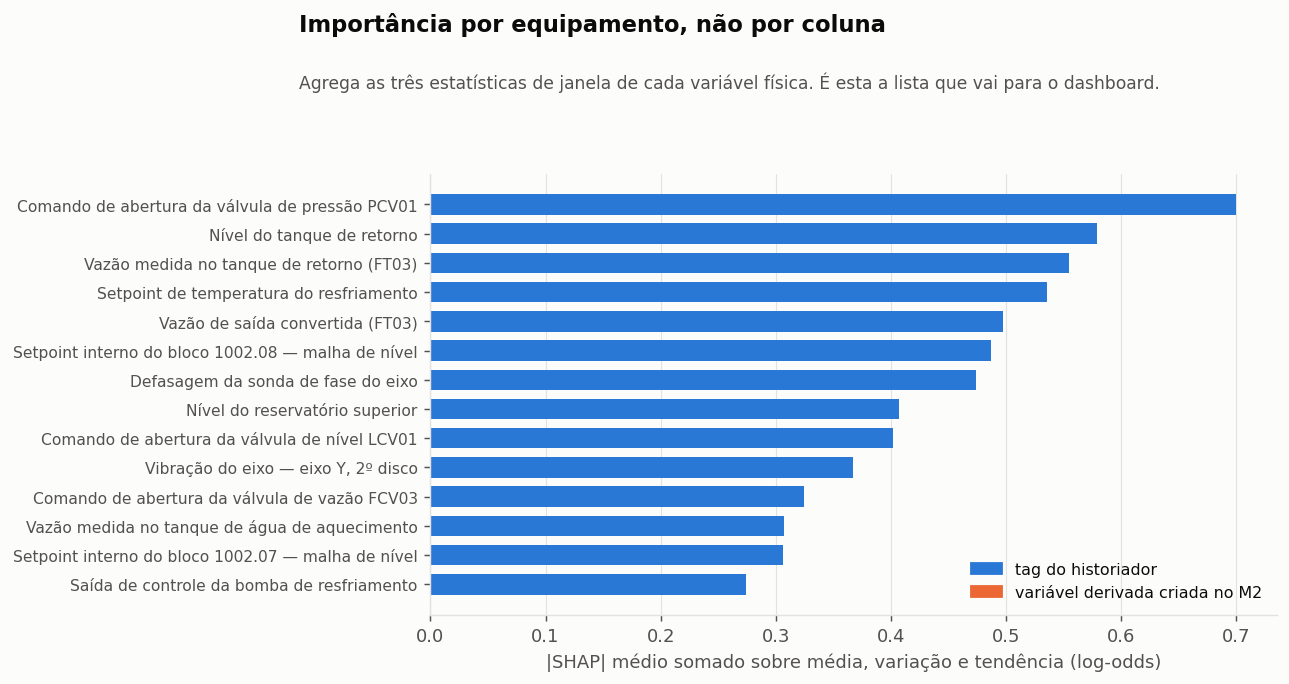

In [6]:
por_tag = su.importancia_por_tag(explicacao).head(14)[::-1]
rot = [rt.rotular(t, com_estatistica=False) for t in por_tag.index]
cor = [S2 if rt.origem(t).startswith('derivada') else S1 for t in por_tag.index]

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.barh(range(len(por_tag)), por_tag.values, color=cor, height=.7)
ax.set_yticks(range(len(por_tag)))
ax.set_yticklabels([f'{r}' for r in rot], fontsize=8.6)
ax.set_xlabel('|SHAP| médio somado sobre média, variação e tendência (log-odds)')
ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=S1, label='tag do historiador'),
                   Patch(color=S2, label='variável derivada criada no M2')], fontsize=8.8, loc='lower right')
titulo(fig, 'Importância por equipamento, não por coluna',
       'Agrega as três estatísticas de janela de cada variável física. É esta a lista que vai para o dashboard.')
fig.savefig(FIGS / 'h2_por_tag.png', bbox_inches='tight'); plt.show()

### 2.3 SHAP concorda com a importância por permutação do M3?

Não exatamente, e a diferença é informativa. A permutação do M3 mede **quanto o PR-AUC cai** ao
embaralhar a variável — é sensibilidade do *desempenho*. O |SHAP| médio mede **quanto a variável
move o logito** — é magnitude do *efeito*. Uma variável pode mover muito o logito em janelas que já
estariam certas de qualquer jeito, e aparecer alta no SHAP sem ser decisiva para a métrica.

In [7]:
imp_shap = su.importancia_por_feature(explicacao)
comp = pd.DataFrame({'posição no SHAP': imp_shap.rank(ascending=False).astype(int),
                     '|SHAP| médio': imp_shap.round(3)}).head(10)
comp.index = [rt.rotular(c) for c in comp.index]
comp

,posição no SHAP,|SHAP| médio
Setpoint de temperatura do resfriamento — média no minuto,1,0.536
Setpoint interno do bloco 1002.08 — malha de nível — média no minuto,2,0.470
Vazão medida no tanque de retorno (FT03) — média no minuto,3,0.440
Comando de abertura da válvula de pressão PCV01 — média no minuto,4,0.432
Defasagem da sonda de fase do eixo — variação no minuto,5,0.385
Vazão de saída convertida (FT03) — média no minuto,6,0.310
Nível do reservatório superior — média no minuto,7,0.288
Nível do tanque de retorno — variação no minuto,8,0.288
Setpoint interno do bloco 1002.07 — malha de nível — média no minuto,9,0.279
Nível do tanque de retorno — média no minuto,10,0.259


---

## 3. SHAP local — por que ESTA janela

A pergunta que a banca faz é sobre um caso. Abaixo, três casos escolhidos para cobrir os três
desfechos possíveis do detector: um acerto, uma falha e um alarme falso.

Cada janela é identificada pelo instante em que começa — é assim que o operador a encontraria no
historiador.

In [8]:
# mapeia cada janela do teste ao ataque que ela cobre
CORTE = meta['corte_teste']
eventos = av.eventos(seg['rotulo'].to_numpy())
ataques['inicio_rel'] = [a for a, _ in eventos]
ataques['fim_rel'] = [b for _, b in eventos]
ini_rel = teste['inicio_seg'].to_numpy() - CORTE
TAM = meta['tamanho_janela']

teste['ataque'] = ''
for r in ataques.itertuples():
    teste.loc[(ini_rel + TAM > r.inicio_rel) & (ini_rel <= r.fim_rel), 'ataque'] = r.id
classe = dict(zip(ataques.id, ataques.classe))
teste['classe'] = teste['ataque'].map(classe).fillna('normal')

resumo = (teste[teste.ataque != '']
          .groupby('ataque')
          .agg(classe=('classe', 'first'), janelas=('prob', 'size'),
               prob_maxima=('prob', 'max'), alarmes=('alarme', 'sum'))
          .join(ataques.set_index('id')[['cenario', 'duracao_s']]))
resumo['detectado'] = np.where(resumo.alarmes > 0, 'sim', '—')
resumo[['cenario', 'classe', 'duracao_s', 'janelas', 'prob_maxima', 'detectado']].round(3)

,cenario,classe,duracao_s,janelas,prob_maxima,detectado
ataque,,,,,,
A221,AE08,interno,82,5,0.200,—
A222,AE01,interno,211,9,0.200,—
A223,AE07,interno,79,4,0.675,—
A224,AP14+AP26,io,107,5,0.995,sim
A225,AP16+AP32,io,60,4,1.000,sim
A226,AP04+AP11,io,118,6,1.000,sim
A227,AP09+AP14,io,132,6,1.000,sim
A228,AP05+AP30,io,155,7,0.993,sim
A229,AP45+AP01,io,115,5,0.293,—


In [9]:
def waterfall(indice, titulo_txt, subtitulo, arquivo, n=12):
    e = shap.Explanation(values=explicacao.values[indice],
                         base_values=float(np.ravel(explicacao.base_values)[indice]),
                         data=X.iloc[indice].to_numpy(),
                         feature_names=[rt.rotular(c) for c in COLUNAS])
    plt.figure()
    shap.plots.waterfall(e, max_display=n, show=False)
    fig = traduzir(plt.gcf()); fig.set_size_inches(9.6, 4.6)
    plt.gca().tick_params(axis='y', labelsize=8.4)
    titulo(fig, titulo_txt, subtitulo)
    fig.savefig(FIGS / arquivo, bbox_inches='tight'); plt.show()

def descreve(i):
    r = teste.iloc[i]
    return (f"janela de {pd.Timestamp(r.instante):%d/%m %H:%M:%S} · probabilidade {r.prob:.3f} · "
            f"limiar {LIMIAR:.3f} · {'ALARME' if r.alarme else 'sem alarme'}")

### 3.1 Um acerto — ataque A226, manipulação de ponto de E/S

A226 é um ataque composto: altera ao mesmo tempo o comando da válvula de pressão PCV01 e o da
válvula de vazão FCV03. É a classe de ataque que o historiador enxerga, porque os pontos
manipulados **são** tags registradas.

janela de 18/08 20:32:31 · probabilidade 1.000 · limiar 0.933 · ALARME


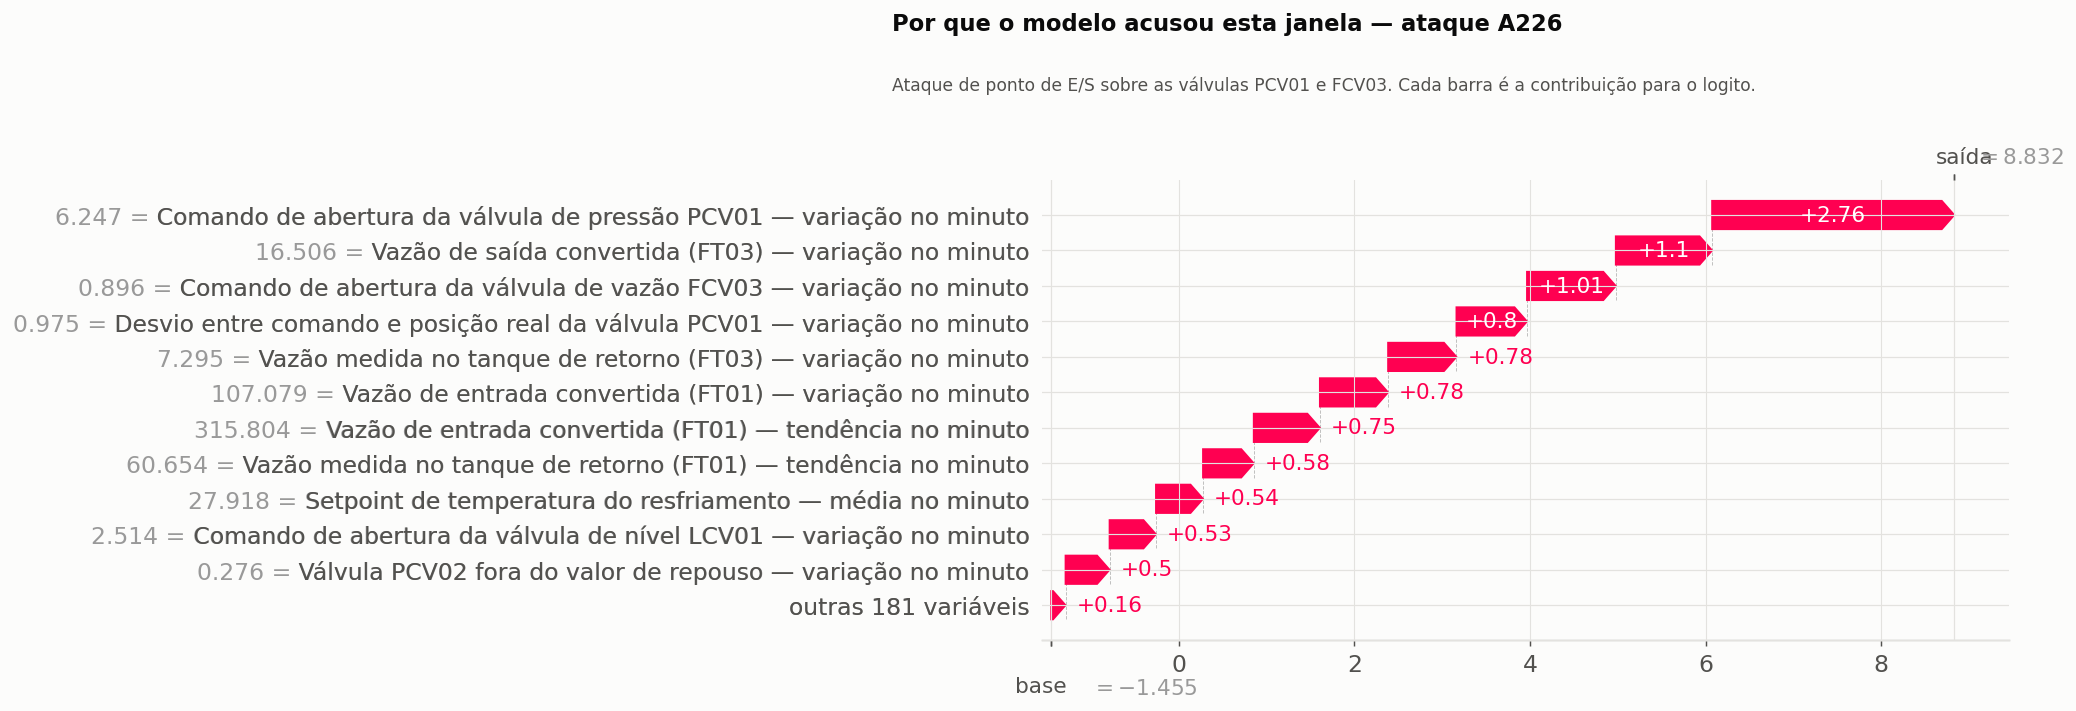

In [10]:
i_a226 = int(teste[teste.ataque == 'A226'].prob.idxmax())
print(descreve(i_a226))
waterfall(i_a226, 'Por que o modelo acusou esta janela — ataque A226',
          'Ataque de ponto de E/S sobre as válvulas PCV01 e FCV03. Cada barra é a contribuição para o logito.',
          'h3_waterfall_acerto.png')

A leitura para a sala de controle é direta: *"a abertura da válvula de pressão PCV01 e o desvio
entre comando e posição real das válvulas estão fora do padrão; a soma dessas evidências colocou a
janela muito acima do limiar."* Nenhuma dessas variáveis, sozinha, dispararia um alarme
convencional de limite — todas estão dentro da faixa operacional. É o **conjunto** que denuncia.

### 3.2 Uma falha — ataque A222, manipulação de ponto interno

A222 é um ataque AE01: altera o valor de inicialização de uma função de E/S artificial do algoritmo
do controlador, de 40 para 12. O ponto manipulado é `1001-09-AVALGEN.R1` — **não existe entre as 86
tags do historiador**.

janela de 18/08 16:20:01 · probabilidade 0.200 · limiar 0.933 · sem alarme


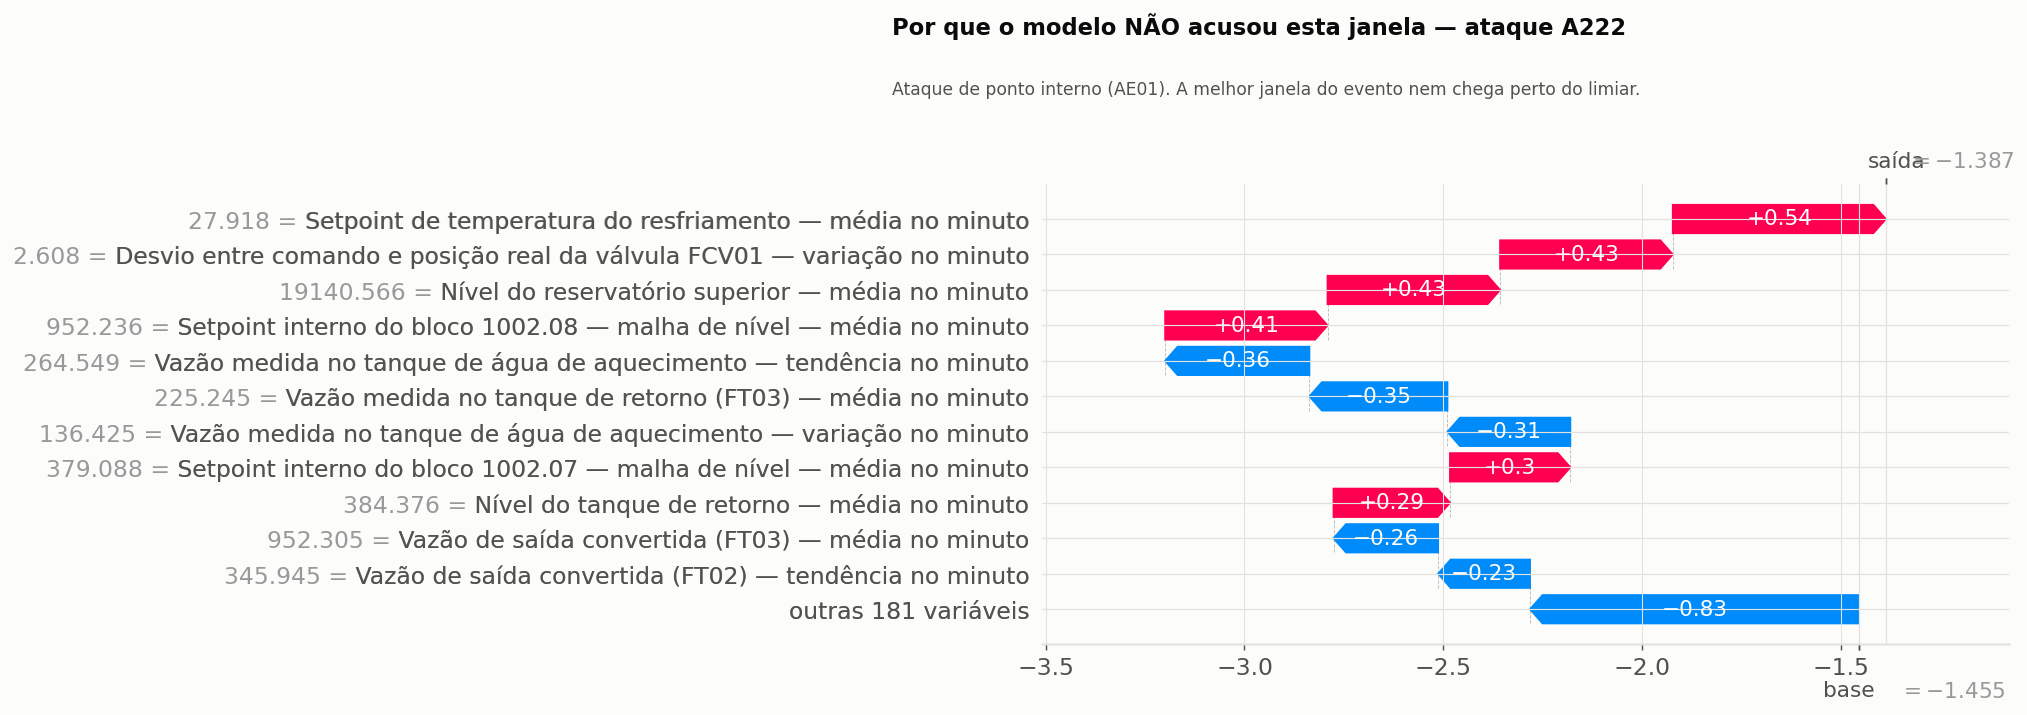

In [11]:
i_a222 = int(teste[teste.ataque == 'A222'].prob.idxmax())
print(descreve(i_a222))
waterfall(i_a222, 'Por que o modelo NÃO acusou esta janela — ataque A222',
          'Ataque de ponto interno (AE01). A melhor janela do evento nem chega perto do limiar.',
          'h4_waterfall_falha.png')

Esse gráfico é mais eloquente pelo que **não** tem. As contribuições são pequenas e se cancelam;
a soma mal se afasta da base. O modelo não "errou por pouco" — ele **não viu nada**. A diferença
entre as duas janelas não é de calibração de limiar, é de informação disponível.

### 3.3 Um alarme falso

janela de 19/08 07:20:31 · probabilidade 1.000 · limiar 0.933 · ALARME


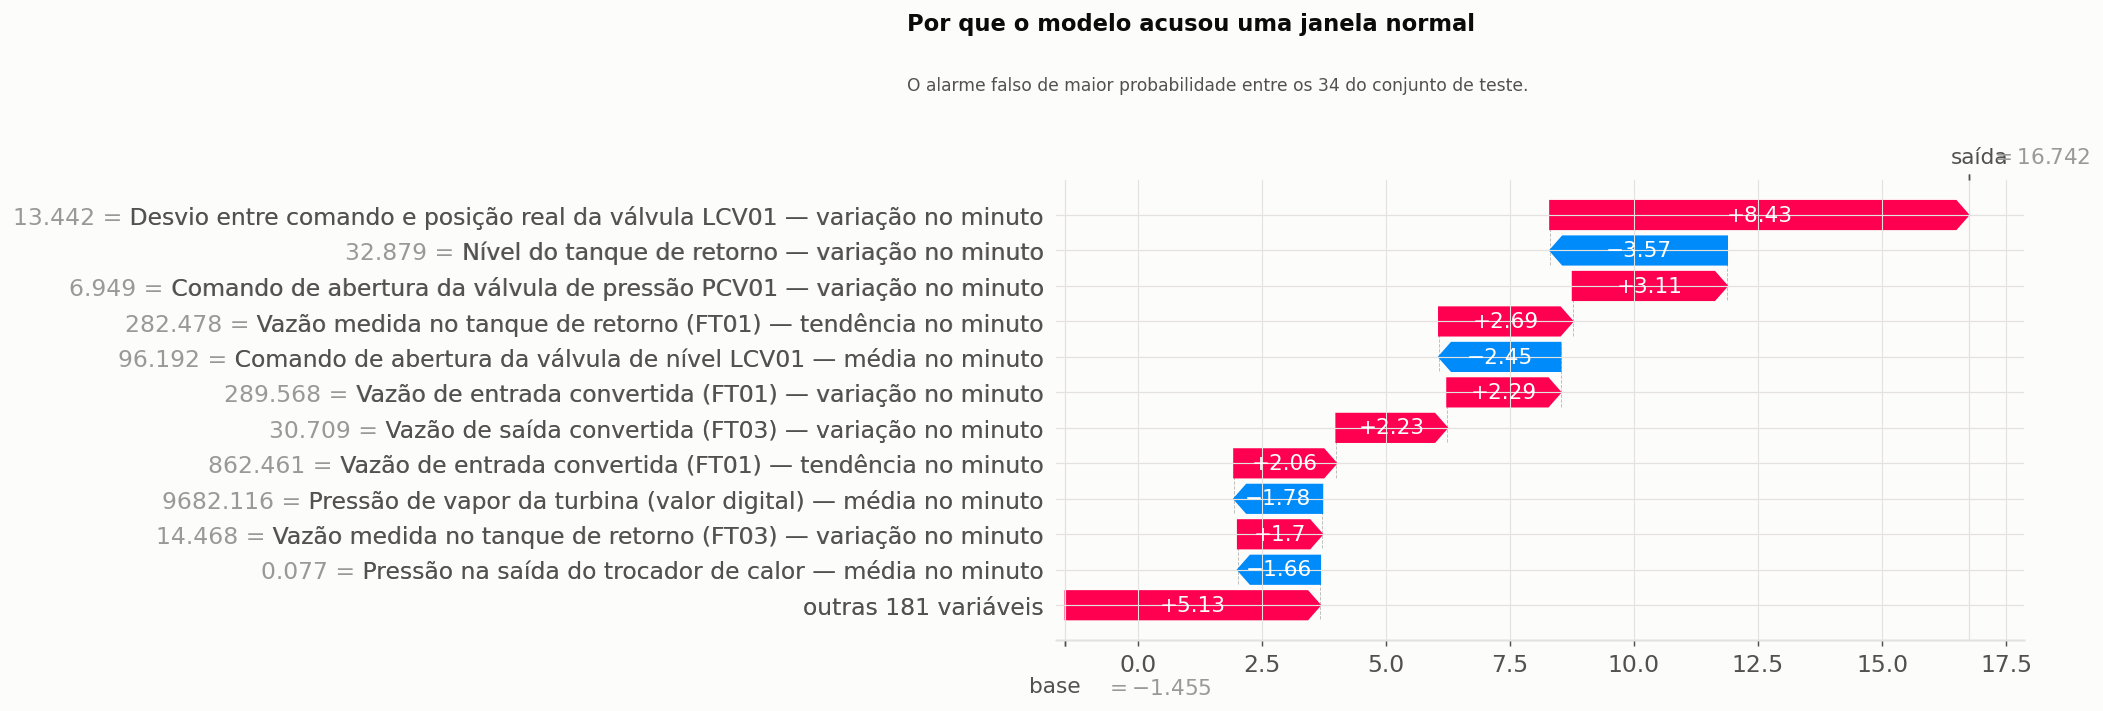

In [12]:
fp = teste[(teste.rotulo == 0) & (teste.alarme == 1)]
i_fp = int(fp.prob.idxmax())
print(descreve(i_fp))
waterfall(i_fp, 'Por que o modelo acusou uma janela normal',
          'O alarme falso de maior probabilidade entre os 34 do conjunto de teste.',
          'h5_waterfall_falso.png')

In [13]:
# quão perto dos ataques estão os alarmes falsos?
def distancia(i):
    a, b = ini_rel[i], ini_rel[i] + TAM
    return min(0 if not (b < x or a > y) else min(abs(a - y), abs(x - b)) for x, y in eventos)

d = np.array([distancia(i) for i in fp.index])
pd.Series({'≤ 1 min de um ataque rotulado': int((d <= 60).sum()),
           '≤ 5 min': int((d <= 300).sum()),
           '≤ 15 min': int((d <= 900).sum()),
           'total de alarmes falsos': len(fp)}).to_frame('janelas')

,janelas
≤ 1 min de um ataque rotulado,4
≤ 5 min,13
≤ 15 min,19
total de alarmes falsos,34


**13 dos 34 alarmes falsos caem a menos de cinco minutos de um ataque rotulado.** O rótulo do
dataset marca a janela em que o atacante estava agindo; o processo leva mais tempo para voltar ao
regime. Parte do que a métrica conta como alarme falso é, na verdade, o detector ainda vendo o
**efeito** do ataque depois que ele terminou.

Isso não é desculpa para inflar o resultado — a métrica do relatório continua contando esses casos
como falso positivo, que é o conservador. Mas muda a leitura operacional: um alarme logo após um
evento confirmado não é ruído, é rastro.

---

## 4. O que o SHAP diz sobre a cegueira a ponto interno

O M3 mostrou **que** os ataques de ponto interno escapam. Com SHAP dá para perguntar algo mais
útil: o modelo chega perto? Se chegasse, baixar o limiar resolveria. A medida é a **massa total de
evidência** que o modelo acumula numa janela — a soma dos |φᵢ|.

In [14]:
grupos = {'operação normal': teste.classe == 'normal',
          'ataque de ponto de E/S': teste.classe == 'io',
          'ataque de ponto interno': teste.classe == 'interno'}
massa = np.abs(explicacao.values).sum(1)

tab = pd.DataFrame([{'grupo': g,
                     'janelas': int(m.sum()),
                     'probabilidade média': round(float(teste.prob[m].mean()), 3),
                     'evidência acumulada Σ|φ|': round(float(massa[m.to_numpy()].mean()), 1),
                     'janelas com alarme': int(teste.alarme[m].sum())}
                    for g, m in grupos.items()]).set_index('grupo')
tab

,janelas,probabilidade média,evidência acumulada Σ|φ|,janelas com alarme
grupo,,,,
operação normal,2886,0.382,10.7,34
ataque de ponto de E/S,141,0.798,43.5,86
ataque de ponto interno,44,0.378,11.0,0


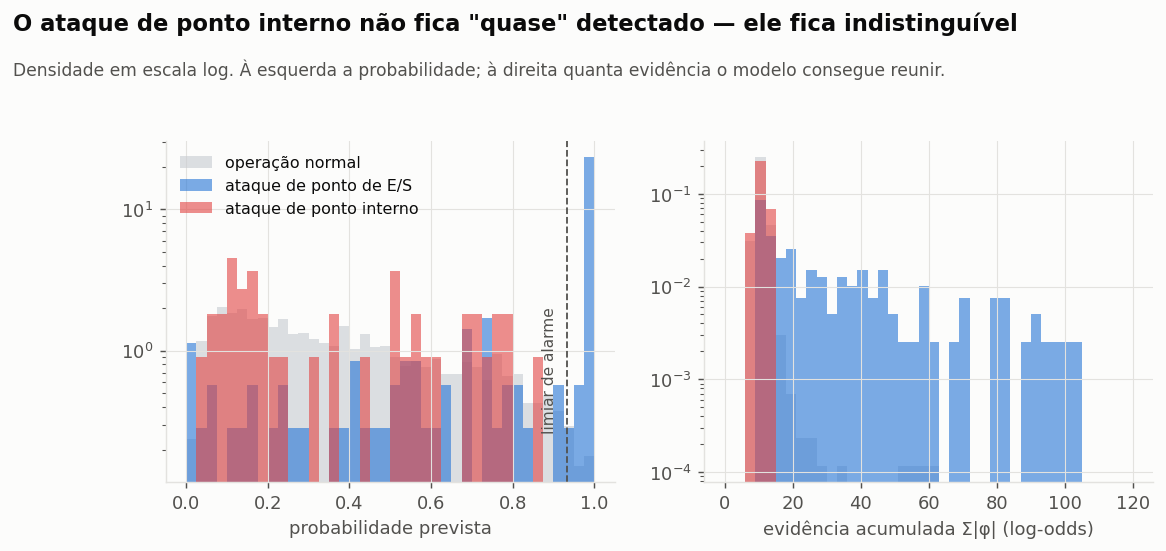

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.4))
cores = {'operação normal': NEU, 'ataque de ponto de E/S': S1, 'ataque de ponto interno': S8}
for ax, (dados, rotulo_x, lim_x) in zip(axes, [
        (teste.prob.to_numpy(), 'probabilidade prevista', (0, 1)),
        (massa, 'evidência acumulada Σ|φ| (log-odds)', (0, 120))]):
    for g, m in grupos.items():
        ax.hist(dados[m.to_numpy()], bins=40, range=lim_x, density=True,
                color=cores[g], alpha=.62, label=g)
    ax.set_xlabel(rotulo_x); ax.set_yticks([]); ax.set_yscale('log')
axes[0].axvline(LIMIAR, color=TXT2, ls='--', lw=1)
axes[0].text(LIMIAR - .025, axes[0].get_ylim()[0] * 2.2, 'limiar de alarme', ha='right',
             fontsize=8.5, color=TXT2, rotation=90, va='bottom')
axes[0].legend(fontsize=8.8, loc='upper left')
titulo(fig, 'O ataque de ponto interno não fica "quase" detectado — ele fica indistinguível',
       'Densidade em escala log. À esquerda a probabilidade; à direita quanta evidência o modelo consegue reunir.')
fig.savefig(FIGS / 'h6_cegueira.png', bbox_inches='tight'); plt.show()

**Esta é a contribuição do M4 ao argumento do projeto.** Sob ataque de ponto de E/S o modelo
reúne cerca de **quatro vezes** mais evidência do que em operação normal, e a probabilidade média
sobe de 0,38 para 0,80. Sob ataque de **ponto interno**, as duas medidas ficam **praticamente iguais
às da operação normal**.

A consequência é operacional, não estatística:

- **Baixar o limiar não resolve.** Para capturar as janelas de ponto interno seria preciso descer o
  limiar até onde a operação normal também dispara — ou seja, trocar 7 detecções por um alarme
  permanente. A curva cobertura × alarme do M3 já mostrava o preço; o SHAP mostra a razão.
- **O que falta é instrumentação, não algoritmo.** O ponto manipulado (um parâmetro interno do
  algoritmo do controlador) não chega ao historiador. Detectar essa classe exige monitorar
  **alteração de lógica e de parâmetros na estação de engenharia** — um controle de outra natureza,
  que nenhum modelo sobre essas 86 tags substitui.

É exatamente isso que o dashboard precisa dizer, em `st.warning()`, antes que alguém confie demais
no número de cobertura.

---

## 5. Limitações da interpretação

1. **Correlação, não causa.** φᵢ diz quanto a variável moveu a saída *deste modelo*, não que ela
   tenha causado o ataque. Com 34 pares de variáveis acima de |r| = 0,95 no dataset (M2), o peso
   atribuído a uma pode estar representando a outra.
2. **A explicação é do modelo, não do fenômeno.** Um modelo diferente, com desempenho parecido,
   pode distribuir o crédito de outro jeito.
3. **Explicação por janela, não por segundo.** A unidade é a janela de 60 s; o SHAP não aponta o
   segundo em que a manipulação começou.
4. **A base depende do fundo escolhido.** `base` é o logito médio sobre 500 janelas de treino
   sorteadas com `random_state=42`. Outro fundo desloca a base — as contribuições relativas se
   mantêm, mas os valores absolutos mudam.
5. **O fundo é do treino.** Se a planta mudar de regime, a referência de "normal" envelhece junto
   com o modelo.

---

## Síntese

| | |
|---|---|
| **Método** | SHAP em forma fechada para modelo linear — exato, erro de aditividade ~10⁻⁶ |
| **Global** | comando de atuador e setpoint interno da malha dominam; nenhuma variável resolve sozinha |
| **Validação da decisão 3 do M2** | os resíduos comando/realimentação aparecem entre os de maior peso |
| **Local** | A226 (ponto de E/S) acumula evidência muito acima do limiar; A222 (ponto interno) não se afasta da base |
| **Alarmes falsos** | 13 dos 34 caem a menos de 5 min de um ataque — rastro, não ruído |
| **Achado do módulo** | sob ataque de ponto interno a evidência é **indistinguível da operação normal** — o problema é instrumentação, não limiar |

---

## Declaração de uso de Inteligência Artificial

Conforme a política da disciplina. Usei assistente de IA (Claude) como ferramenta de apoio: revisão
do material das aulas, discussão de alternativas, revisão de código e redação. **As decisões de
método, de escopo e de interpretação são minhas**, tomadas após avaliar as alternativas registradas
neste caderno e em `prompts_log.md`, na raiz do repositório.